In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math


**Task 1**


true       : 0.5403023058681398
forward  h=1e-5: 0.5402980985058647
central  h=1e-5: 0.5403023058569989


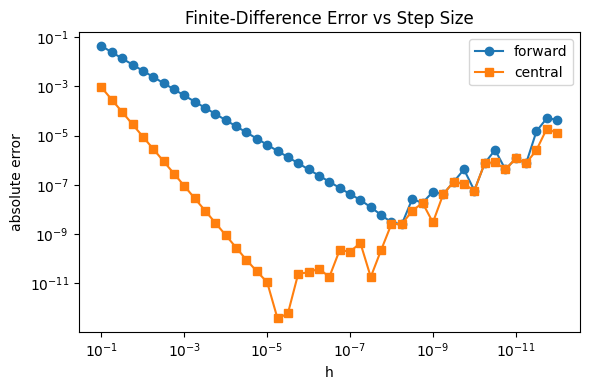

best h, forward: 5.623413251903491e-09
best h, central: 5.623413251903491e-06
Task 1 OK


In [ ]:
def f(x):
  return np.sin(x)

def df_true(x):
  return np.cos(x)

def deriv_forward(f, x, h):
  return (f(x+h)-f(x))/h

def deriv_central(f, x, h):
  return (f(x+h)-f(x-h))/(2*h)

x0 = 1.0

print("true       :", df_true(x0))
print("forward  h=1e-5:", deriv_forward(f, x0, 1e-5))
print("central  h=1e-5:", deriv_central(f, x0, 1e-5))

hs = np.logspace(-1, -12, 45)

err_fwd = np.array([
    abs(deriv_forward(f, x0, h) - df_true(x0))
    for h in hs
])
err_ctr = np.array([
    abs(deriv_central(f, x0, h) - df_true(x0))
    for h in hs
])

plt.figure(figsize=(6, 4))
plt.loglog(hs, err_fwd, "o-", label="forward")
plt.loglog(hs, err_ctr, "s-", label="central")
plt.gca().invert_xaxis()

plt.xlabel("h")
plt.ylabel("absolute error")
plt.legend()
plt.title("Finite-Difference Error vs Step Size")
plt.tight_layout()
plt.show()

print("best h, forward:", hs[np.argmin(err_fwd)])
print("best h, central:", hs[np.argmin(err_ctr)])
assert abs(
    deriv_central(f, x0, 1e-5) - df_true(x0)
) < 1e-7

print("Task 1 OK")


для forward h нужен маленький, 10^-9 чтобы достичь лучшей точности, а для централ нужен большой h 10^-6.



*   Which method gives a smaller error near its optimal h?
Central derivative gives smaller error

*   Why does the error eventually increase when h becomes extremely small?
I guess because our sinusoid function changes sharply and with smaller h the other side doesn't balance this rapid change and also because when h is very small, f(x+h) and f(x) become nearly same and subtracting them causes same cancellation

*   Why is the central-difference method generally more accurate than the forward-difference method?
Because central difference consideres not only right side, but both sides from x so that curvness balances




true       : 6
forward  h=1e-5: 6.000009999951316
central  h=1e-5: 6.000000000039306


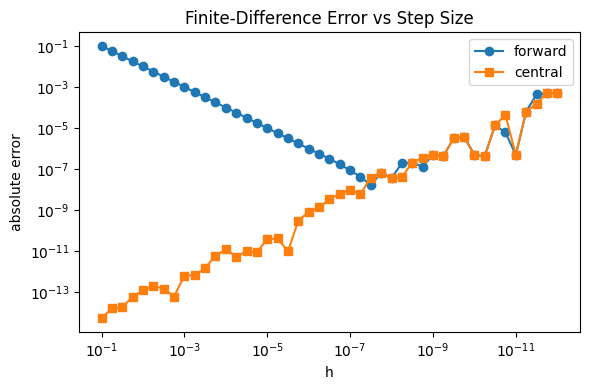

best h, forward: 3.162277660168379e-08
best h, central: 0.1
Optional task is ok


In [ ]:
def f(x):
  return x**2

def df_true(x):
  return 2*x

x0 = 3
print("true       :", df_true(x0))
print("forward  h=1e-5:", deriv_forward(f, x0, 1e-5))
print("central  h=1e-5:", deriv_central(f, x0, 1e-5))

err_fwd = np.array([
    abs(deriv_forward(f, x0, h) - df_true(x0))
    for h in hs
])
err_ctr = np.array([
    abs(deriv_central(f, x0, h) - df_true(x0))
    for h in hs
])

plt.figure(figsize=(6, 4))
plt.loglog(hs, err_fwd, "o-", label="forward")
plt.loglog(hs, err_ctr, "s-", label="central")
plt.gca().invert_xaxis()

plt.xlabel("h")
plt.ylabel("absolute error")
plt.legend()
plt.title("Finite-Difference Error vs Step Size")
plt.tight_layout()
plt.show()

print("best h, forward:", hs[np.argmin(err_fwd)])
print("best h, central:", hs[np.argmin(err_ctr)])
assert abs(
    deriv_central(f, x0, 1e-5) - df_true(x0)
) < 1e-7
print("Optional task is ok")

Explain why the central-difference curve behaves differently from the sin(𝑥) experiment.
Bescause derivatives of sin(x) is cos(x) then, second derivative is again -sin(x) and it is never 0. For x^2 first derivative is 2x, second is 2 and third is 0.

In [ ]:
def f(x):
  return abs(x)

x0 = 0
print("forward  h=1e-5:", deriv_forward(f, x0, 1e-5))
print("central  h=1e-5:", deriv_central(f, x0, 1e-5))

forward  h=1e-5: 1.0
central  h=1e-5: 0.0


Explain what happens at the corner.
At the corner, the derivative equals 0 and the tangent line is parallel to ox.

**Task 2**

In [ ]:
rng = np.random.default_rng(0)

def f(w):
  return w[0]**2 + 3*w[0]*w[1] + 2*w[1]**2
def grad_analytic(w):
  der_w0 = 2*w[0] + 3*w[1]
  der_w1 = 3*w[0] + 4*w[1]
  return np.array([der_w0, der_w1])
def numeric_gradient(f, w, h=1e-5):
  g = np.zeros_like(w, dtype=float)
  for i in range(len(w)):
    w_plus = w.copy()
    w_minus = w.copy()
# TODO:
# perturb ONLY coordinate i
# calculate the central difference
    w_plus[i] += h
    w_minus[i] -= h
    g[i] = (f(w_plus)-f(w_minus))/(2*h)
  return g
w = np.array([1.0, 2.0])
ga = grad_analytic(w)
gn = numeric_gradient(f, w)
print("f(w) =", f(w))
print("analytic grad =", ga)
print("numeric grad =", gn)
print(
"max abs diff =",
np.max(np.abs(ga - gn))
)
eps = 1e-3
d_grad = ga / np.linalg.norm(ga)
gain_grad = f(w + eps * d_grad) - f(w)
gains_random = []
for _ in range(20):
  d = rng.normal(size=2)
  d /= np.linalg.norm(d)
  gains_random.append(
  f(w + eps * d) - f(w)
  )
print("gain along gradient :", gain_grad)
print("best random gain :", max(gains_random))
assert np.allclose(ga, [8.0, 11.0])
assert np.max(np.abs(ga - gn)) < 1e-6
assert gain_grad >= max(gains_random) - 1e-9
print("Task 2 OK")

f(w) = 15.0
analytic grad = [ 8. 11.]
numeric grad = [ 8. 11.]
max abs diff = 1.1647038888895622e-10
gain along gradient : 0.013604551589814662
best random gain : 0.013554948328849292
Task 2 OK


1. What is the difference between a derivative and a gradient?
gradient is like derivative with multiple inputs
2. Why do we use .copy() when creating w_plus and w_minus?
because we want to copy and make changes from one w and add or subtract h and we don't want to change w.
3. Why must we perturb one coordinate at a time when calculating the gradient?
we want to see changes according one axis. And because partial derivatives measures how function changes if we change only one variable at once with other being fixed
4. What does it mean that the gradient points in the direction of steepest ascent?
we find derivative according one variable not changing others with each of them and we get a vector which tells us in which direction function increases faster

Create a contour plot of 𝑓(𝑤1,𝑤2) for 𝑤1,𝑤2∈[−3,3]. Use plt.contour() and overlay the gradient at [1,2] using plt.quiver().

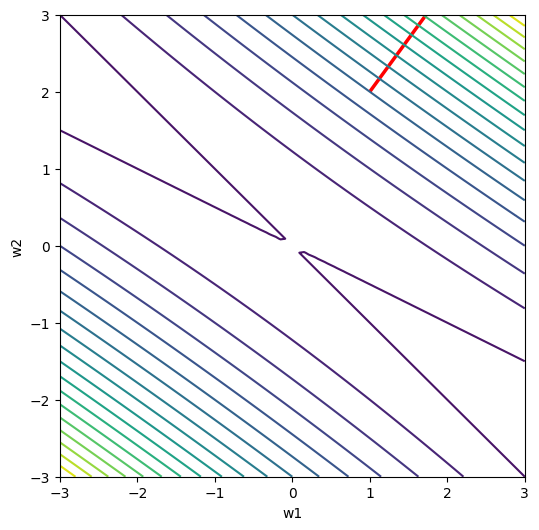

In [ ]:
w1_range = np.linspace(-3, 3, 100)
w2_range = np.linspace(-3, 3, 100)
W1, W2 = np.meshgrid(w1_range, w2_range)
Z = f([W1, W2])
plt.figure(figsize=(6,6))
plt.contour(W1, W2, Z, levels=20)

w_point = np.array([1.0, 2.0])
grad_at_point = grad_analytic(w_point)

plt.quiver(w_point[0], w_point[1], grad_at_point[0], grad_at_point[1],
           color='red', angles='xy', scale_units='xy', scale=1)
plt.xlabel("w1")
plt.ylabel("w2")
plt.show()

Explain why the gradient is perpendicular to the contour line.
Because along contour line values of the function stay the same and gradient shows the direction where the function increases fast that's why the gradient is perpendicular to the contour line.

**Task 3**

In [ ]:
def sigmoid(z):
  return 1.0 / (1.0 + np.exp(-z))

def forward(w, b, x, y):
  z = w * x + b
  a = sigmoid(z)
  L = -(y * np.log(a) + (1 - y) * np.log(1 - a))
  return z, a, L

def grad_analytic(w, b, x, y):
  z, a, L = forward(w, b, x, y)
  dL_da = -y / a + (1 - y) / (1 - a)
  da_dz = a * (1 - a)
  dz_dw = x
  dz_db = 1.0
  dL_dw = dL_da * da_dz * dz_dw
  dL_db = dL_da * da_dz * dz_db
  return dL_dw, dL_db

def numeric_gradient_wb(w, b, x, y, h=1e-5):
  _, _, L_w_plus  = forward(w + h, b, x, y)
  _, _, L_w_minus = forward(w - h, b, x, y)
  dL_dw = (L_w_plus - L_w_minus) / (2 * h)
  _, _, L_b_plus  = forward(w, b + h, x, y)
  _, _, L_b_minus = forward(w, b - h, x, y)
  dL_db = (L_b_plus - L_b_minus) / (2 * h)
  return dL_dw, dL_db

x, y = 2.0, 1.0
w, b = 0.3, -0.1
z, a, L = forward(w, b, x, y)
print("z, a, L =", z, a, L)
dL_dw, dL_db = grad_analytic(w, b, x, y)
print("analytic dL/dw, dL/db =", dL_dw, dL_db)
ndw, ndb = numeric_gradient_wb(w, b, x, y)
print("numeric dL/dw, dL/db =", ndw, ndb)
assert abs(dL_dw - ndw) < 1e-6
assert abs(dL_db - ndb) < 1e-6
print("Task 3 OK")

z, a, L = 0.5 0.6224593312018546 0.47407698418010663
analytic dL/dw, dL/db = -0.7550813375962909 -0.37754066879814546
numeric dL/dw, dL/db = -0.7550813376056008 -0.37754066880002485
Task 3 OK


1. What is the chain rule doing in this example?
The chain rule works backwards multipliyng derivative of outer function on inner function thats what backpropagation is
2. Why does the gradient contain several factors multiplied together?
because we have to consider all the inner factors such as pre-activation, weight. Little changes in each of them matter
3. Why is ∂𝐿/∂𝑤 exactly twice ∂𝐿/∂𝑏 for these particular values?
because outer derivative of 2g(x) is 2
4. Why is numerical gradient checking useful?
because wrong calculation can lead to wrong decision

**Task 4**

In [ ]:
X = np.array([
    [1.0, 2.0],
    [2.0, 0.5],
    [3.0, 1.0],
    [4.0, 3.0],
])
w = np.array([2.0, -1.0]) # shape (2,)
b = 0.5
def predict(X, w, b):
  # TODO: return X @ w + b, shape should be (4,)
  return X @ w + b
yhat = predict(X, w, b)
print("yhat shape:", yhat.shape)
print("yhat :", yhat)
# --- Now deliberately introduce a shape bug ---
w_bad = w.reshape(2, 1) # shape (2, 1) instead of (2,)
yhat_bad = X @ w_bad + b
print("yhat_bad shape:", yhat_bad.shape)
print("yhat_bad :", yhat_bad)
assert yhat.shape == (4,)
assert yhat_bad.shape == (4, 1)
print("Task 4 OK")

yhat shape: (4,)
yhat : [0.5 4.  5.5 5.5]
yhat_bad shape: (4, 1)
yhat_bad : [[0.5]
 [4. ]
 [5.5]
 [5.5]]
Task 4 OK


1. What does each dimension of X represent?
first dimension is like a number of records/observations and the second is like a number of features
2. What does the shape (2,) of w represent?
It is one-dimensional array of two weights, each weight is for each feature
3. Why is the correct prediction shape (4,)?
4 predictions for each record
4. Why does changing w to shape (2,1) change the prediction shape?
because dimension of multiplication of matrices will differ
5. Why can a shape such as (4,1) be dangerous even though the values look correct?
because further calculation will differ

**Task 5**

In [ ]:
X = np.array([
    [1.0, 2.0],
    [2.0, 0.5],
    [3.0, 1.0],
    [4.0, 3.0],
])
w = np.array([2.0, -1.0])
b = 0.5
y = np.array([1.0, 2.0, 3.0, 4.0])

yhat = X @ w + b
def mse_loop(yhat, y):
    total = 0.0
    for i in range(len(yhat)):
        total += (yhat[i] - y[i]) ** 2
    return total / len(yhat)
def mse_vec(yhat, y):
    return np.mean((yhat - y) ** 2)
m1 = mse_loop(yhat, y)
m2 = mse_vec(yhat, y)
print("loop:", m1, "vec:", m2)
assert abs(m1 - m2) < 1e-12
w_bad = w.reshape(2, 1)
yhat_bad = X @ w_bad + b
print("yhat_bad shape:", yhat_bad.shape)

diff = yhat_bad - y
print("diff shape:", diff.shape)

mse_bad = np.mean(diff ** 2)
print("MSE bad:", mse_bad)

loop: 3.1875 vec: 3.1875
yhat_bad shape: (4, 1)
diff shape: (4, 4)
MSE bad: 7.3125


1. Calculate the residuals by hand.
residual = yhat - y
i = 0, res = -0.5
i = 1, res = 2
i = 2, res = 2.5
i = 3, res = 1.5
2. Calculate the MSE by hand.
MSE = sum(res^2)/4 = 3.1875
3. Why do the loop and vectorised implementations give the same answer?
because both of them calculate one mathematical metric but numpy executes faster
4. Why does subtracting (4,) from (4,1) produce an array of shape (4,4)?
because broadcasting happens(expansion of smaller array) to make calculations possible
5. Why is this a dangerous bug?
because there is no alert, danger is in silent failure

**Task 6**

In [2]:
x = np.array([1.0, 2.0, 3.0])
y = np.array([2.0, 4.0, 5.0])
w = 0
b = 0
learning_rate = 0.1
def predict(x, w, b):
    return w * x + b

def mse_loss(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

def analytical_gradients(x, y, w, b):
    y_pred = predict(x, w, b)

    dw = (2 / len(x)) * np.sum((y_pred - y) * x)
    db = (2 / len(x)) * np.sum(y_pred - y)

    return dw, db

def numerical_gradient_w(x, y, w, b, h=1e-5):
    loss_plus = mse_loss(y, predict(x, w + h, b))
    loss_minus = mse_loss(y, predict(x, w - h, b))

    return (loss_plus - loss_minus) / (2 * h)


def numerical_gradient_b(x, y, w, b, h=1e-5):
    loss_plus = mse_loss(y, predict(x, w, b + h))
    loss_minus = mse_loss(y, predict(x, w, b - h))

    return (loss_plus - loss_minus) / (2 * h)

y_pred = predict(x, w, b)
initial_loss = mse_loss(y, y_pred)

print("Initial predictions:", y_pred)
print("Initial loss:", initial_loss)

dw, db = analytical_gradients(x, y, w, b)

print("Analytical dw:", dw)
print("Analytical db:", db)

dw_num = numerical_gradient_w(x, y, w, b)
db_num = numerical_gradient_b(x, y, w, b)

print("Numerical dw:", dw_num)
print("Numerical db:", db_num)

print("dw difference:", abs(dw - dw_num))
print("db difference:", abs(db - db_num))

assert np.allclose(dw, dw_num)
assert np.allclose(db, db_num)

w = w - learning_rate * dw
b = b - learning_rate * db

print("New w:", w)
print("New b:", b)

y_pred_new = predict(x, w, b)
new_loss = mse_loss(y, y_pred_new)

print("New predictions:", y_pred_new)
print("New loss:", new_loss)

print("Loss decreased:", new_loss < initial_loss)

assert new_loss < initial_loss

print("Task 6 OK")

Initial predictions: [0. 0. 0.]
Initial loss: 15.0
Analytical dw: -16.666666666666664
Analytical db: -7.333333333333333
Numerical dw: -16.666666666687036
Numerical db: -7.333333333026103
dw difference: 2.0371260234242072e-11
db difference: 3.072297971584703e-10
New w: 1.6666666666666665
New b: 0.7333333333333334
New predictions: [2.4        4.06666667 5.73333333]
New loss: 0.2340740740740741
Loss decreased: True
Task 6 OK


1. Why are both gradients negative?
because the model predictions are too small compared with real values
2. Why does subtracting a negative gradient increase w and b?
because we are subtracting negative number
3. Why must both gradients be calculated before updating the parameters?
because gradients will be calculated using wrong parameters
4. What happens if you use w + η·gw instead of w - η·gw?
that will move a parameter to the opposite direction
5. Why is checking whether the loss decreased a useful debugging tool?
because if the loss increases that could mean there is a mistake in calculations or parameters

**Final reflection**

1. What is the relationship between a derivative and a gradient?
the derivative with multiple inputs is a gradient-a vector containing the partial derivative with respect to every input.
The gradient says which way to turn every knob
2. What does the chain rule have to do with backpropagation?
a network is a composition, we have to consider every parameter and
3. Why is numerical gradient checking useful?
it is important to analyze if our analytical gradient is correct
4. Why are array shapes important in machine learning?
because it can tell us the number of records or features, or it effects on mathematical calculations
5. What are the four main steps of gradient descent?
forward pass
loss
gradient
update the parameters